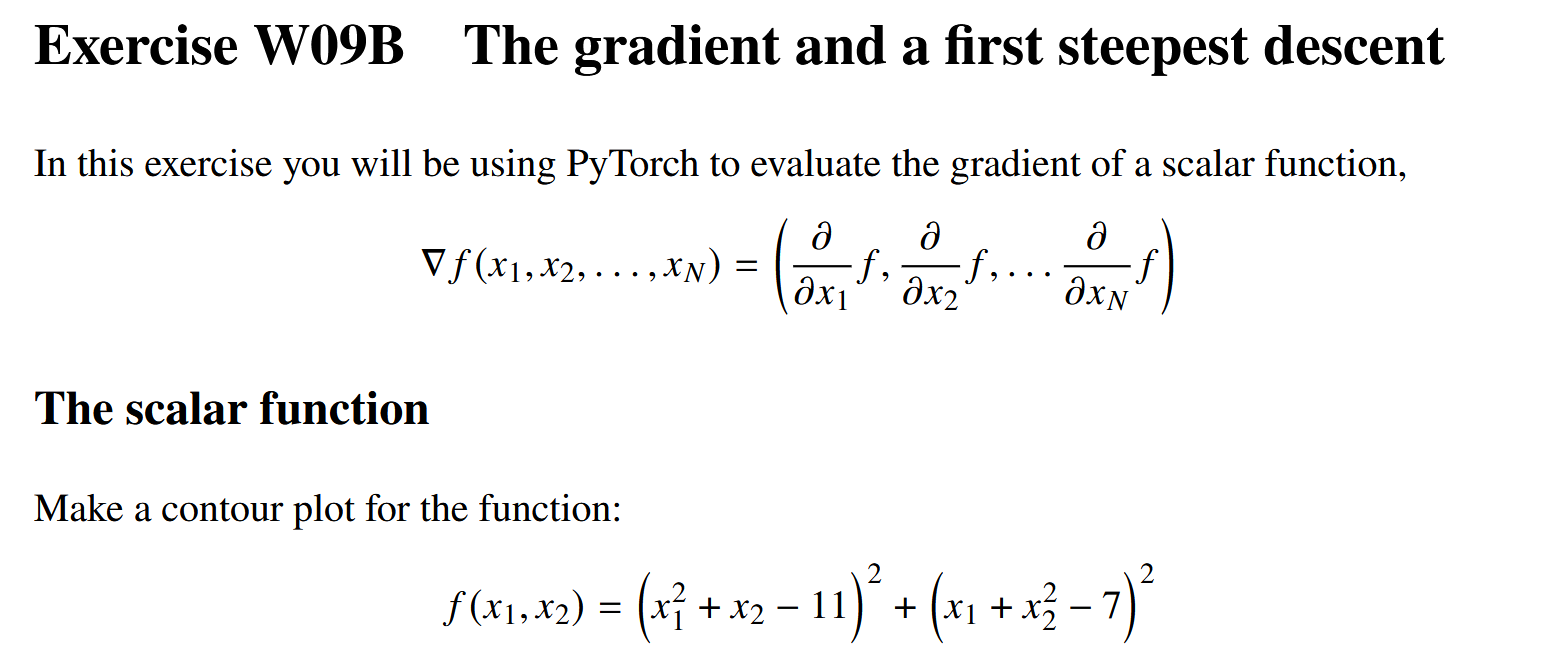
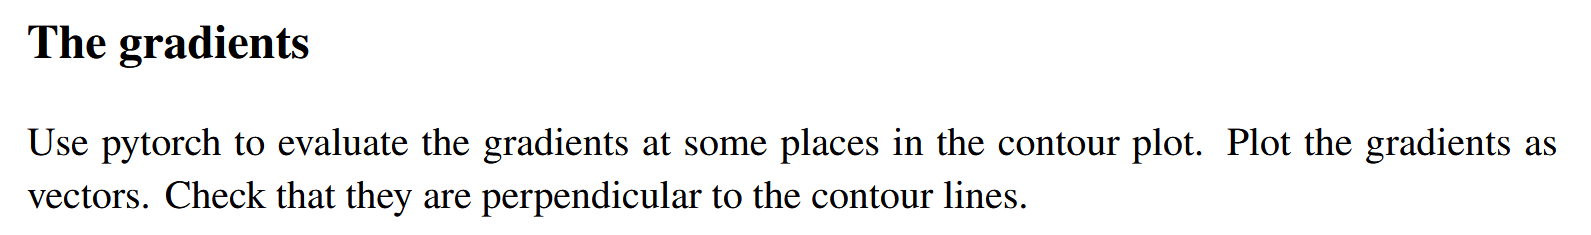

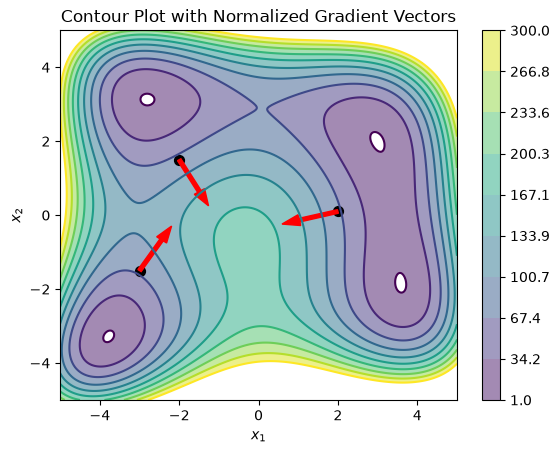

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

def f(x1, x2):
    return (x1**2 + x2 - 11)**2 + (x1 + x2**2 - 7)**2

vals = np.linspace(-5, 5, 1000)

x1d, x2d = np.meshgrid(vals, vals)
yd = f(x1d, x2d)



# Plot contour 
fig, ax = plt.subplots()
levels = np.linspace(1, 300, 10)
ax.contour(x1d, x2d, yd, levels=levels)
color_map = ax.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
fig.colorbar(color_map, ax=ax)
ax.set(xlabel='$x_1$', ylabel='$x_2$')


# Gradiants 
for P0 in [[-2, 1.5], [2, 0.1], [-3, -1.5]]:
    P0 = torch.tensor(P0, dtype=torch.float32, requires_grad=True)

    f_val = f(P0[0], P0[1])
    f_val.backward()

    grad_y = P0.grad.numpy()
    P0 = P0.detach().numpy()

    v = grad_y/np.linalg.norm(grad_y)

    ax.scatter(*P0, s=50, c='k')
    ax.arrow(*P0, *v, width=0.1, color='red')

plt.title("Contour Plot with Normalized Gradient Vectors")
plt.show()

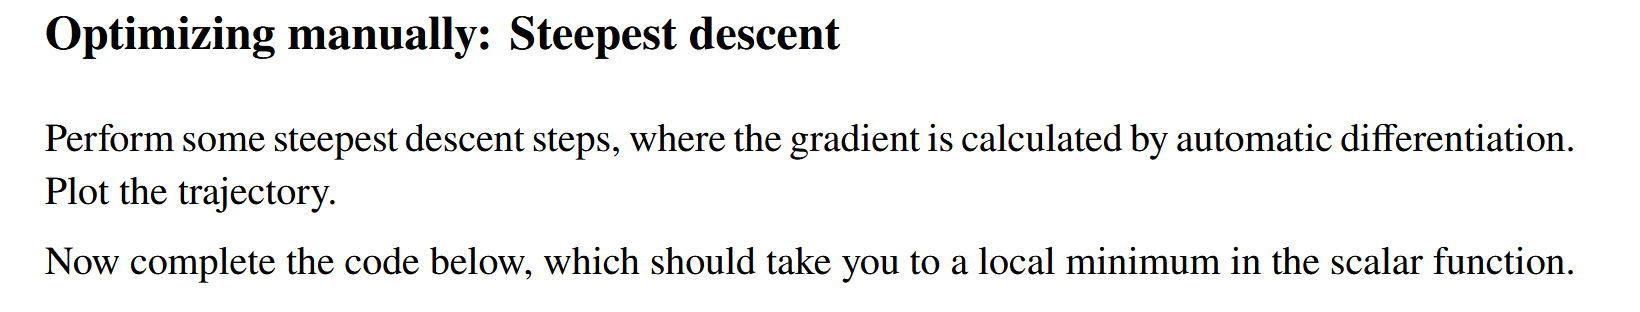

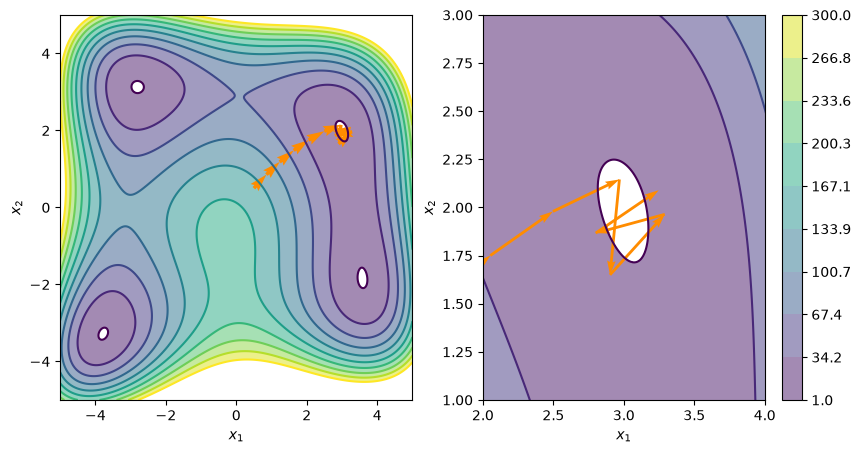

In [35]:
P0 = torch.tensor([0.5, 0.5], requires_grad=True)

zero_gradiant = True

points = []
grads = []
points.append(P0.detach().numpy().copy())

for _ in range(10):
    if zero_gradiant and P0.grad is not None:
        P0.grad.zero_()

    y = f(P0[0], P0[1])
    y.backward()
    grad = P0.grad

    with torch.no_grad():
        v = grad / torch.norm(grad)
        step_size = 0.5 
        P0 -= v * step_size
        points.append(P0.detach().numpy().copy())

# Plot contour 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
levels = np.linspace(1, 300, 10)
ax1.contour(x1d, x2d, yd, levels=levels)
color_map = ax1.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
fig.colorbar(color_map, ax=ax2)
ax1.set(xlabel='$x_1$', ylabel='$x_2$')

X, Y = np.array(points).T
ax1.quiver(X[:-1], Y[:-1], np.diff(X), np.diff(Y), 
          angles='xy', scale_units='xy', scale=1, 
          facecolor='darkorange', edgecolor='black', width=0.01)

ax2.contour(x1d, x2d, yd, levels=levels)
ax2.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
ax2.set(xlabel='$x_1$', ylabel='$x_2$', 
        xlim=(2, 4), ylim=(1, 3))
ax2.quiver(X[:-1], Y[:-1], np.diff(X), np.diff(Y), 
          angles='xy', scale_units='xy', scale=1, 
          facecolor='darkorange', edgecolor='black', width=0.01)


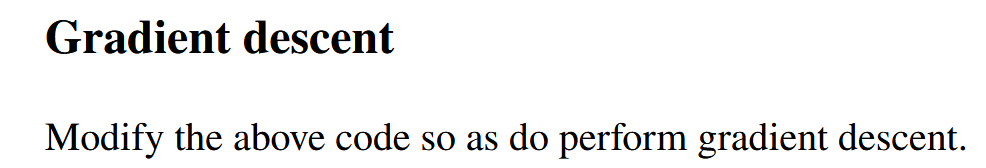

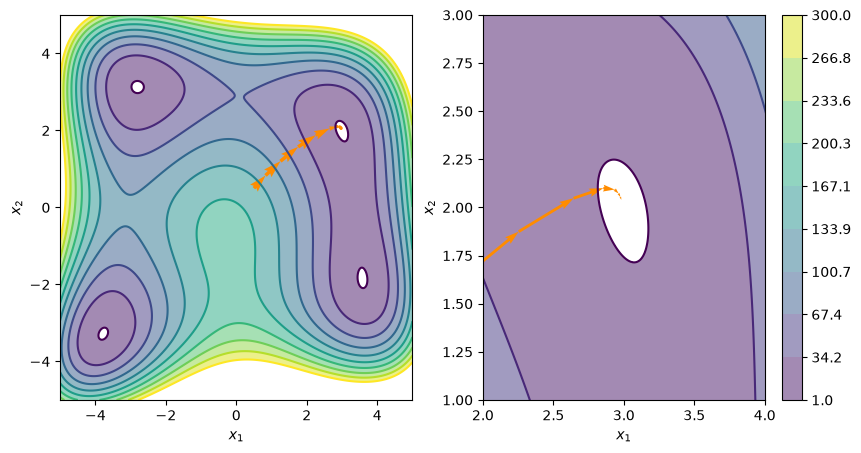

In [ ]:
P0 = torch.tensor([0.5, 0.5], requires_grad=True)

points = []
points.append(P0.detach().numpy().copy())

for _ in range(10):
    if zero_gradiant and P0.grad is not None:
        P0.grad.zero_()

    y = f(P0[0], P0[1])
    y.backward()
    grad = P0.grad

    with torch.no_grad():
        v = grad
        learning_rate = 0.01
        P0 -= v * learning_rate
        points.append(P0.detach().numpy().copy())

# Plot contour 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
levels = np.linspace(1, 300, 10)
ax1.contour(x1d, x2d, yd, levels=levels)
color_map = ax1.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
fig.colorbar(color_map, ax=ax2)
ax1.set(xlabel='$x_1$', ylabel='$x_2$')

X, Y = np.array(points).T
ax1.quiver(X[:-1], Y[:-1], np.diff(X), np.diff(Y), 
          angles='xy', scale_units='xy', scale=1, 
          facecolor='darkorange', edgecolor='black', width=0.01)

ax2.contour(x1d, x2d, yd, levels=levels)
ax2.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
ax2.set(xlabel='$x_1$', ylabel='$x_2$', 
        xlim=(2, 4), ylim=(1, 3))
ax2.quiver(X[:-1], Y[:-1], np.diff(X), np.diff(Y), 
          angles='xy', scale_units='xy', scale=1, 
          facecolor='darkorange', edgecolor='black', width=0.01)


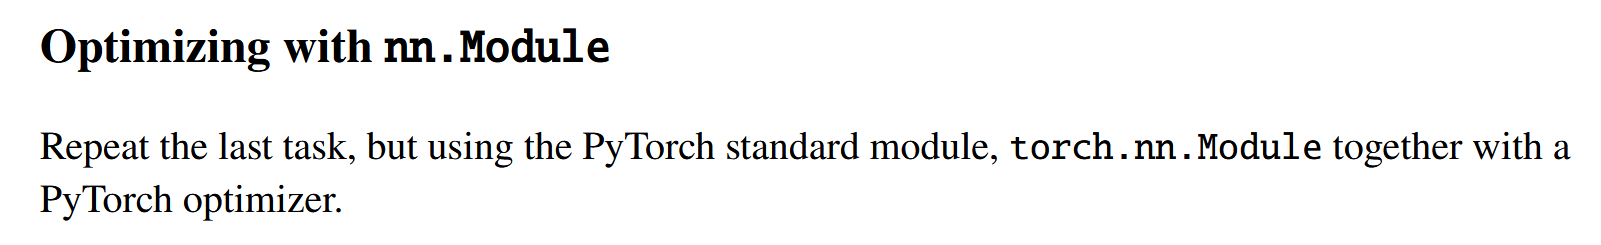

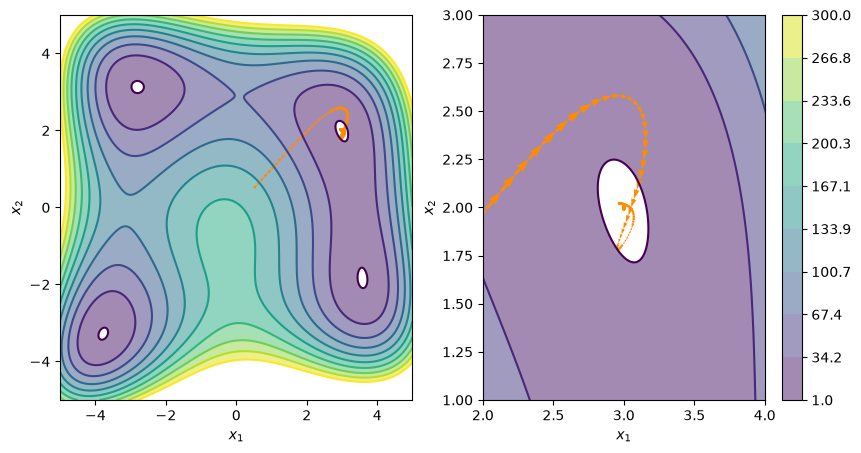

In [44]:
class ScalarFiels(nn.Module):
    def __init__(self, *args, func, P0 = [0.5, 0.5], **kwargs):
        super().__init__(*args, **kwargs)
        self.f = func
        self.P0 = nn.Parameter(torch.tensor(P0, dtype=torch.float32, requires_grad=True))

    def forward(self):
        return self.f(self.P0[0], self.P0[1])


P0 = torch.tensor([0.5, 0.5], requires_grad=True)

points = []
points.append(P0.detach().numpy().copy())

model = ScalarFiels(func=f)

optimizer = optim.Adam(model.parameters(), lr=0.1)

for _ in range(500):
    optimizer.zero_grad()
    loss = model()
    loss.backward()

    optimizer.step()
    points.append(model.P0.detach().numpy().copy())

# Plot contour 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
levels = np.linspace(1, 300, 10)
ax1.contour(x1d, x2d, yd, levels=levels)
color_map = ax1.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
fig.colorbar(color_map, ax=ax2)
ax1.set(xlabel='$x_1$', ylabel='$x_2$')

X, Y = np.array(points).T
ax1.quiver(X[:-1], Y[:-1], np.diff(X), np.diff(Y), 
          angles='xy', scale_units='xy', scale=1, 
          facecolor='darkorange', edgecolor='black', width=0.01)

ax2.contour(x1d, x2d, yd, levels=levels)
ax2.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
ax2.set(xlabel='$x_1$', ylabel='$x_2$', 
        xlim=(2, 4), ylim=(1, 3))
ax2.quiver(X[:-1], Y[:-1], np.diff(X), np.diff(Y), 
          angles='xy', scale_units='xy', scale=1, 
          facecolor='darkorange', edgecolor='black', width=0.01)
